# 🌾 Reto AgroCebada 2026: modelo de predicción de rendimiento
**Metodología CRISP-DM · Colab** · 197 parcelas (Puebla, Hidalgo y Tlaxcala) · ciclo abril-octubre 2025

**Cómo usar este cuaderno en Colab**
1. Abre Colab y sube este archivo (*Archivo → Subir cuaderno*).
2. Ejecuta todo (*Entorno de ejecución → Ejecutar todas*). Cuando lo pida, sube `tabla_variables_agrocebada.csv`.
3. Al final se descargan `predicciones_59_parcelas.csv` (parcelas del reto) y `pesos_variables.csv`.

**Qué hace:** homogeneiza las variables, les asigna un **peso**, compara algoritmos con validación cruzada, entrena el modelo final y genera las predicciones. El mismo modelo (`modelo.py`) es el que usa la aplicación web en Streamlit.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
VERDE, AZUL, GRIS, ROJO = "#3B7D23", "#1F5F8B", "#9AA5A0", "#C0392B"

ARCHIVO = "tabla_variables_agrocebada.csv"
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        print("Sube el archivo tabla_variables_agrocebada.csv")
        subido = files.upload(); ARCHIVO = list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError("Coloca tabla_variables_agrocebada.csv junto a este cuaderno.")
t0 = pd.read_csv(ARCHIVO)
print(t0.shape)

(197, 156)


## Fase 1 · Comprensión del negocio
- **Objetivo:** estimar el rendimiento (t/ha) de 59 parcelas de cebada con rendimiento oculto, a partir de 138 parcelas con rendimiento conocido.
- **Métricas:** RMSE, MAE y R² (las que pide el reto).
- **Uso final:** una aplicación web que ejecute el modelo y permita consultar resultados (30 % de la calificación) y apoye la inclusión financiera en el sector agro.

## Código del modelo (`modelo.py`)
Esta celda escribe el módulo que contiene el algoritmo; la aplicación web usa **exactamente el mismo archivo**. Se explica en las fases 3 y 4.

In [2]:
%%writefile modelo.py
"""Modelo final del Reto AgroCebada 2026.

Predicción = media de rendimiento del municipio + corrección.
La corrección es una regresión Ridge sobre variables HOMOGENEIZADAS:
  1) cada variable se expresa como anomalía (diferencia respecto al promedio de su municipio, o de su grupo de
     municipios pequeños) -> elimina el efecto de ubicación y deja lo que distingue a la parcela de su zona;
  2) los faltantes se imputan con la mediana;
  3) se estandarizan (z-score) para que todas tengan la misma escala.
Los coeficientes del Ridge sobre variables estandarizadas son los PESOS de las variables.
"""
import re
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

SEED = 42
ALPHAS = np.logspace(1, 4, 20)


# ---------------------------------------------------------------- variables candidatas y anomalías
def columnas_candidatas(t):
    num = t.select_dtypes("number").columns.drop(["rendimiento_t_ha", "lat", "lon"], errors="ignore")
    meses = tuple(f"_m{m:02d}" for m in (2, 3, 4, 5, 6, 7))
    cand = [c for c in num if c.startswith(("pl_", "s2_")) and any(m in c for m in meses)]
    cand += [c for c in ("pl_evi_pico", "pl_ndvi_pico", "pl_evi_auc_mar_jul", "pl_ndvi_auc_mar_jul",
                         "pl_ndvi_std_mar_jul", "pl_evi_pend_abr_jun", "pl_ndvi_pend_abr_jun",
                         "elevacion_m", "pendiente_grados", "area_ha") if c in t.columns]
    cand += [c for c in num if c.startswith(("prec_m0", "tmin_m0", "tmax_m0")) and c[-2:] in ("04", "05", "06", "07")]
    cand += [c for c in ("prec_ciclo", "prec_abr_jun", "tmed_ciclo", "amp_ciclo") if c in t.columns]
    return list(dict.fromkeys(cand))


def agregar_anomalias(t):
    """Devuelve (tabla con columnas *_anom, lista de columnas de anomalía)."""
    t = t.copy()
    n_mun = t.groupby("Municipio").ID_POLIGONO.transform("count")
    t["_ref"] = np.where(n_mun >= 5, t.Municipio, "EST_" + t.Estado)
    cand = columnas_candidatas(t)
    A = t[cand].sub(t.groupby("_ref")[cand].transform("mean")).add_suffix("_anom")
    return pd.concat([t, A], axis=1), list(A.columns)


def media_loo(d):
    """Media del municipio sin contar la propia parcela (evita fuga de información al ajustar)."""
    g = d.groupby("Municipio").rendimiento_t_ha
    s, n = g.transform("sum"), g.transform("count")
    return ((s - d.rendimiento_t_ha) / (n - 1)).where(n > 1, d.groupby("Estado").rendimiento_t_ha.transform("mean"))


class Zonas:
    """Promedios de referencia por zona para convertir valores de una parcela nueva en anomalías."""
    def __init__(self, t):
        self.cand = columnas_candidatas(t)
        n_mun = t.groupby("Municipio").ID_POLIGONO.transform("count")
        ref = np.where(n_mun >= 5, t.Municipio, "EST_" + t.Estado)
        self.medias = t[self.cand].groupby(ref).mean()
        self.global_ = t[self.cand].mean()
        self.ok_mun = set(t.Municipio[n_mun >= 5])
        self.mun_estado = t.drop_duplicates("Municipio").set_index("Municipio").Estado.to_dict()

    def clave(self, mun, est):
        if mun in self.ok_mun: return mun
        if f"EST_{est}" in self.medias.index: return f"EST_{est}"
        return None

    def referencia(self, mun, est):
        k = self.clave(mun, est)
        return self.global_ if k is None else self.medias.loc[k]

    def anomalias(self, df):
        """Para cada fila: valor - promedio de su zona. Si falta el valor de una variable, la anomalía es 0."""
        out = pd.DataFrame(0.0, index=df.index, columns=[c + "_anom" for c in self.cand])
        for i, r in df.iterrows():
            ref = self.referencia(r.get("Municipio"), r.get("Estado"))
            for c in self.cand:
                if c in df.columns and pd.notna(r[c]):
                    out.at[i, c + "_anom"] = float(r[c]) - float(ref[c])
        return out


# ---------------------------------------------------------------- modelo
class ModeloAgroCebada:
    def __init__(self, cols):
        self.cols = cols

    def fit(self, d):
        self.mun = d.groupby("Municipio").rendimiento_t_ha.mean()
        self.est = d.groupby("Estado").rendimiento_t_ha.mean()
        self.glob = d.rendimiento_t_ha.mean()
        if not self.cols:                       # sin variables: queda solo la media del municipio
            self.pipe = None
            return self
        self.pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=ALPHAS))
        self.pipe.fit(d[self.cols], (d.rendimiento_t_ha - media_loo(d)).values)
        return self

    @property
    def alpha(self):
        return float(self.pipe.named_steps["ridgecv"].alpha_)

    def base(self, df):
        return np.array([self.mun.get(m, self.est.get(e, self.glob)) for m, e in zip(df.Municipio, df.Estado)])

    def correccion(self, df):
        return np.zeros(len(df)) if self.pipe is None else self.pipe.predict(df[self.cols])

    def predict(self, df):
        return self.base(df) + self.correccion(df)

    def pesos(self):
        """Peso de cada variable = coeficiente Ridge sobre la variable estandarizada (y su % del total)."""
        coef = self.pipe.named_steps["ridgecv"].coef_
        d = pd.DataFrame({"variable": [c.replace("_anom", "") for c in self.cols], "coeficiente": coef})
        d["peso_pct"] = d.coeficiente.abs() / d.coeficiente.abs().sum() * 100
        d["etiqueta"] = d.variable.map(etiqueta)
        d["grupo"] = d.variable.map(grupo_variable)
        d["familia_indice"] = d.variable.map(familia_indice)
        return d.sort_values("peso_pct", ascending=False).reset_index(drop=True)

    def contribuciones(self, df):
        """Aporte de cada variable (coeficiente x valor estandarizado) a la corrección de una parcela."""
        z = self.pipe.named_steps["standardscaler"].transform(self.pipe.named_steps["simpleimputer"].transform(df[self.cols]))
        coef = self.pipe.named_steps["ridgecv"].coef_
        return pd.Series(z[0] * coef, index=[etiqueta(c) for c in self.cols]).sort_values(key=abs, ascending=False)


def predecir_nuevas(modelo, zonas, df, q10, q90):
    """Predice parcelas nuevas a partir de valores crudos (Municipio es obligatorio; el resto es opcional)."""
    df = df.loc[:, ~df.columns.duplicated()].reset_index(drop=True).copy()
    if "Estado" not in df.columns: df["Estado"] = np.nan
    df["Estado"] = df.Estado.fillna(df.Municipio.map(zonas.mun_estado))
    X = pd.concat([df[["Municipio", "Estado"]], zonas.anomalias(df)], axis=1)
    base, cor = modelo.base(X), modelo.correccion(X)
    out = pd.DataFrame({"Municipio": df.Municipio, "Estado": df.Estado, "media_municipio": base, "correccion": cor,
                        "rendimiento_predicho": base + cor})
    out["p10"], out["p90"] = out.rendimiento_predicho + q10, out.rendimiento_predicho + q90
    if "area_ha" in df.columns:
        out["produccion_esperada_t"] = out.rendimiento_predicho * df.area_ha.astype(float)
    return out, X


# ---------------------------------------------------------------- etiquetas y grupos
_MESES = {"01": "enero", "02": "febrero", "03": "marzo", "04": "abril", "05": "mayo", "06": "junio",
          "07": "julio", "08": "agosto", "09": "septiembre", "10": "octubre"}
_IND = {"ndvi": "NDVI", "evi": "EVI", "ndwi": "NDWI", "msi": "MSI", "crc": "CRC", "dswi2": "DSWI2"}


def etiqueta(col):
    c = col.replace("_anom", "")
    m = re.fullmatch(r"(pl|s2)_([a-z0-9]+)_m(\d\d)", c)
    if m:
        s = "Planet" if m.group(1) == "pl" else "Sentinel-2"
        return f"{s} {_IND.get(m.group(2), m.group(2))} {_MESES[m.group(3)]}"
    m = re.fullmatch(r"(prec|tmin|tmax)_m(\d\d)", c)
    if m:
        n = {"prec": "Precipitación", "tmin": "Tmin", "tmax": "Tmax"}[m.group(1)]
        return f"{n} {_MESES[m.group(2)]}"
    otros = {"pl_evi_pico": "Planet EVI pico", "pl_ndvi_pico": "Planet NDVI pico",
             "pl_evi_auc_mar_jul": "Planet EVI área bajo la curva (mar-jul)",
             "pl_ndvi_auc_mar_jul": "Planet NDVI área bajo la curva (mar-jul)",
             "pl_ndvi_std_mar_jul": "Planet NDVI heterogeneidad (mar-jul)",
             "pl_evi_pend_abr_jun": "Planet EVI cambio abril→junio",
             "pl_ndvi_pend_abr_jun": "Planet NDVI cambio abril→junio",
             "elevacion_m": "Elevación (m)", "pendiente_grados": "Pendiente (°)", "area_ha": "Área (ha)",
             "prec_ciclo": "Precipitación del ciclo", "prec_abr_jun": "Precipitación abr-jun",
             "tmed_ciclo": "Temperatura media del ciclo", "amp_ciclo": "Amplitud térmica del ciclo"}
    return otros.get(c, c)


def grupo_variable(col):
    c = col.replace("_anom", "")
    if c.startswith("pl_"): return "Satelital: Planet"
    if c.startswith("s2_"): return "Satelital: Sentinel-2"
    if c.startswith(("prec", "tmin", "tmax", "tmed", "amp")): return "Clima"
    return "Topografía y parcela"


def familia_indice(col):
    m = re.match(r"^(pl|s2)_(ndvi|evi|ndwi|msi|crc|dswi2)", col.replace("_anom", ""))
    if not m: return None
    return f"{'Planet' if m.group(1) == 'pl' else 'Sentinel-2'} {_IND[m.group(2)]}"


Writing modelo.py


In [3]:
from modelo import (agregar_anomalias, ModeloAgroCebada, Zonas, predecir_nuevas, media_loo, grupo_variable,
                    etiqueta, SEED)

## Fase 2 · Comprensión de los datos
La tabla tiene **una fila por parcela**: los CSV satelitales (una fila por fecha y parcela) se resumieron en promedios mensuales; clima y topografía son el valor del píxel donde cae el centroide de cada parcela. El detalle de cada columna está en el diccionario de datos.

Parcelas: 197 | columnas: 156
{'ENTRENAMIENTO': 138, 'PREDICCION': 59}


,parcelas,media,desv,minimo,maximo
Estado,,,,,
Hidalgo,36,3.76,0.78,2.00,4.87
Puebla,71,4.48,0.58,2.15,5.59
Tlaxcala,31,2.98,0.38,2.50,3.50


Columnas con faltantes: {'rendimiento_t_ha': 59, 'pendiente_grados': 3}


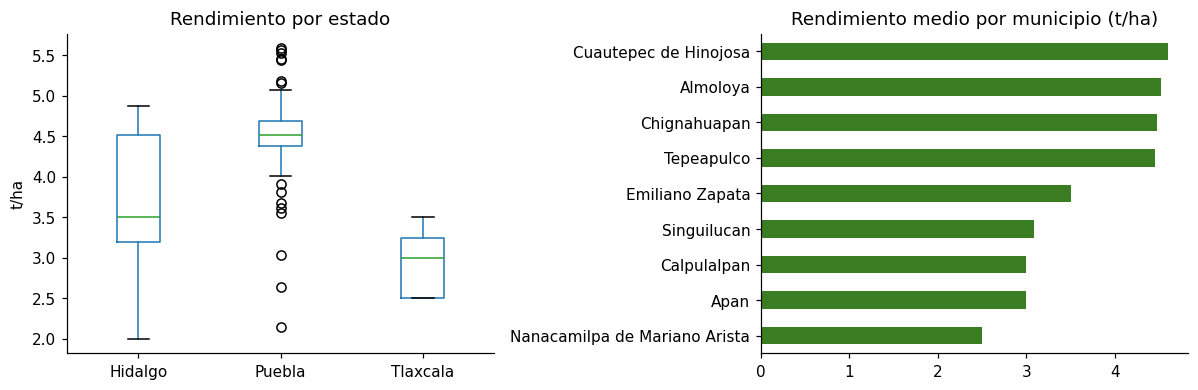

In [4]:
print("Parcelas:", len(t0), "| columnas:", t0.shape[1])
print(t0.conjunto.value_counts().to_dict())
resumen = (t0[t0.conjunto == "ENTRENAMIENTO"].groupby("Estado").rendimiento_t_ha
           .agg(parcelas="count", media="mean", desv="std", minimo="min", maximo="max").round(2))
display(resumen)
nulos = t0.isna().sum(); print("Columnas con faltantes:", nulos[nulos > 0].to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
tr0 = t0[t0.conjunto == "ENTRENAMIENTO"]
tr0.boxplot(column="rendimiento_t_ha", by="Estado", ax=ax[0], grid=False); ax[0].set_title("Rendimiento por estado"); ax[0].set_xlabel(""); fig.suptitle("")
ax[0].set_ylabel("t/ha")
tr0.groupby("Municipio").rendimiento_t_ha.agg(["mean", "count"]).sort_values("mean").plot.barh(y="mean", ax=ax[1], legend=False, color=VERDE)
ax[1].set_title("Rendimiento medio por municipio (t/ha)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

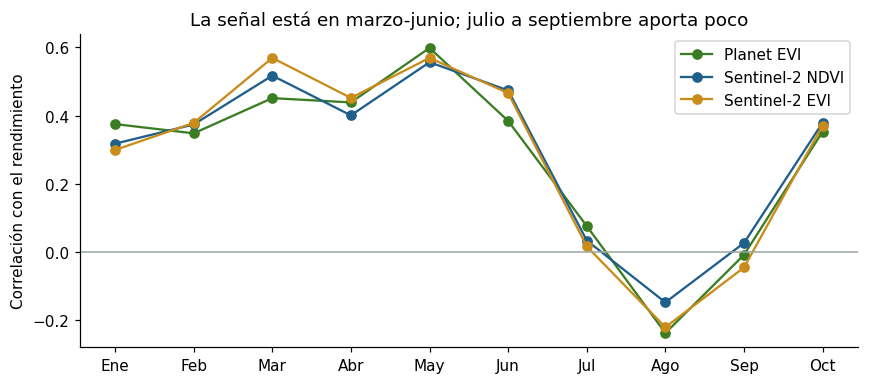

In [5]:
# ¿En qué meses se relacionan más los índices con el rendimiento? (correlación simple, parcelas de entrenamiento)
meses = range(1, 11); etq = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for pref, nom, col in [("pl_evi", "Planet EVI", VERDE), ("s2_ndvi", "Sentinel-2 NDVI", AZUL), ("s2_evi", "Sentinel-2 EVI", "#C98B1A")]:
    r = [tr0[f"{pref}_m{m:02d}"].corr(tr0.rendimiento_t_ha) for m in meses]
    ax.plot(etq, r, marker="o", label=nom, color=col)
ax.axhline(0, color=GRIS, lw=1); ax.set_ylabel("Correlación con el rendimiento"); ax.legend(); ax.set_title("La señal está en marzo-junio; julio a septiembre aporta poco")
plt.tight_layout(); plt.show()

**Hallazgos de esta fase**
- El estado y el municipio explican gran parte del rendimiento (Puebla ≈ 4.5 t/ha; Tlaxcala ≈ 3.0 t/ha).
- Los índices de vegetación se relacionan con el rendimiento sobre todo de marzo a junio.
- El clima tiene resolución de ~5 km: las 197 parcelas caen en solo 25 píxeles, así que parte de su señal es en realidad ubicación.

## Fase 3 · Preparación: homogeneización de las variables
Las variables vienen en escalas y unidades muy distintas (mm de lluvia, °C, índices entre -1 y 1, metros…) y mezclan el efecto de la ubicación con el de la parcela. Para poder compararlas y asignarles un peso se **homogeneizan en tres pasos**:

1. **Anomalía:** valor de la parcela − promedio de su zona (su municipio; el estado si el municipio tiene menos de 5 parcelas). Elimina el efecto de ubicación y deja lo que distingue a la parcela de sus vecinas.
2. **Imputación:** los pocos faltantes (3 pendientes) se llenan con la mediana.
3. **Estandarización (z-score):** media 0 y desviación 1, para que todas queden en la misma escala. Se ajusta **solo con los datos de entrenamiento de cada pliegue** para no filtrar información.

74 variables candidatas homogeneizadas (anomalías).


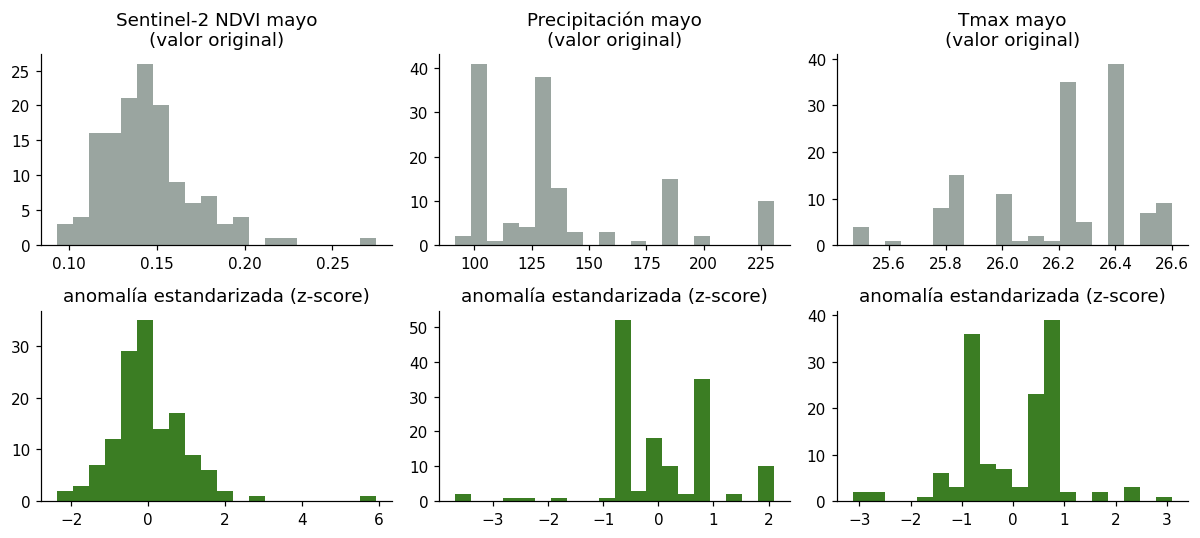

Tras estandarizar: media = 0.0 | desviación = 1.004


In [6]:
t, anom = agregar_anomalias(t0)
tr = t[t.conjunto == "ENTRENAMIENTO"].reset_index(drop=True)
y = tr.rendimiento_t_ha.values
print(f"{len(anom)} variables candidatas homogeneizadas (anomalías).")

# Antes y después de homogeneizar, para 3 variables de escalas muy distintas
from sklearn.preprocessing import StandardScaler
ej = ["s2_ndvi_m05", "prec_m05", "tmax_m05"]
fig, ax = plt.subplots(2, 3, figsize=(11, 5))
for j, v in enumerate(ej):
    ax[0, j].hist(tr[v], bins=20, color=GRIS); ax[0, j].set_title(f"{etiqueta(v)}\n(valor original)")
    z = StandardScaler().fit_transform(tr[[v + "_anom"]])
    ax[1, j].hist(z, bins=20, color=VERDE); ax[1, j].set_title("anomalía estandarizada (z-score)")
plt.tight_layout(); plt.show()
z_all = pd.DataFrame(StandardScaler().fit_transform(tr[anom].fillna(tr[anom].median())), columns=anom)
print("Tras estandarizar: media =", round(z_all.mean().abs().max(), 6), "| desviación =", round(z_all.std().mean(), 3))

## Fase 4 · Modelado y evaluación
**Validación** (138 parcelas con rendimiento):
- *Aleatoria*: 5 pliegues × 3 repeticiones.
- *Agrupada por píxel climático*: parcelas del mismo píxel de 5 km nunca quedan en entrenamiento y prueba a la vez; es más exigente porque parcelas vecinas se parecen.

**Esquema de todos los modelos:** predicción = media del municipio + corrección aprendida sobre las variables homogeneizadas.

,Algoritmo,RMSE aleat.,MAE aleat.,R² aleat.,RMSE agrup.,MAE agrup.,R² agrup.
0,Línea base (media del municipio),0.496,0.325,0.658,0.527,0.366,0.613
1,Ridge ponderado (modelo final),0.494,0.337,0.660,0.523,0.367,0.619
2,Random Forest,0.503,0.357,0.649,0.538,0.395,0.598
3,Extra Trees,0.502,0.354,0.650,0.529,0.385,0.612
4,Gradient Boosting,0.535,0.377,0.601,0.610,0.441,0.483


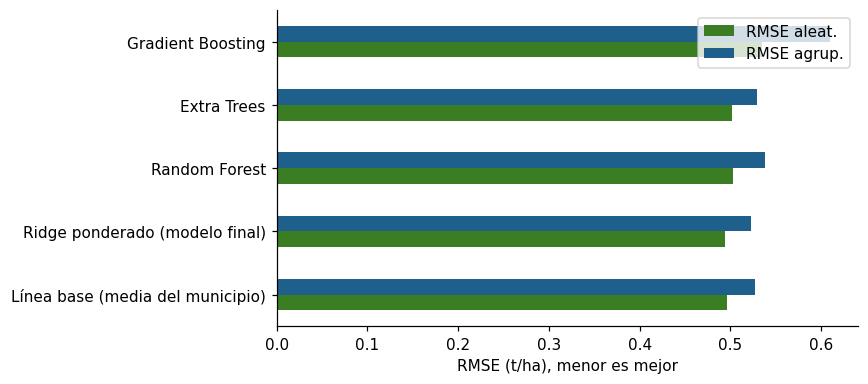

In [7]:
from sklearn.model_selection import RepeatedKFold, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

tr["pixel"] = (np.floor((tr.lon + 99.94999880716205) / 0.05).astype(int).astype(str) + "_" +
               np.floor((21.39999957382679 - tr.lat) / 0.05).astype(int).astype(str))
rk = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(tr))
gk = list(GroupKFold(n_splits=5).split(tr, groups=tr.pixel))

def metricas(p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

def cv_modelo(splits, make=None, cols=anom):
    """make=None -> línea base; make=ModeloAgroCebada -> modelo final; otro -> corrección con ese algoritmo."""
    oof, k = np.zeros(len(y)), np.zeros(len(y))
    for a, b in splits:
        d, db = tr.iloc[a], tr.iloc[b]
        base = ModeloAgroCebada([]).fit(d).base(db)
        if make is None:
            p = base
        elif make is ModeloAgroCebada:
            p = ModeloAgroCebada(cols).fit(d).predict(db)
        else:
            m = make(); m.fit(d[cols], (d.rendimiento_t_ha - media_loo(d)).values); p = base + m.predict(db[cols])
        oof[b] += p; k[b] += 1
    return oof / k

imp = lambda: SimpleImputer(strategy="median")
algoritmos = {
    "Línea base (media del municipio)": None,
    "Ridge ponderado (modelo final)": ModeloAgroCebada,
    "Random Forest": lambda: make_pipeline(imp(), RandomForestRegressor(300, min_samples_leaf=5, max_features=0.33, random_state=SEED, n_jobs=-1)),
    "Extra Trees": lambda: make_pipeline(imp(), ExtraTreesRegressor(300, min_samples_leaf=5, max_features=0.33, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting": lambda: make_pipeline(imp(), GradientBoostingRegressor(n_estimators=120, learning_rate=0.03, max_depth=2, subsample=0.7, random_state=SEED)),
}
filas = []
for nom, mk in algoritmos.items():
    a, g = metricas(cv_modelo(rk, mk)), metricas(cv_modelo(gk, mk))
    filas.append({"Algoritmo": nom, "RMSE aleat.": a["RMSE"], "MAE aleat.": a["MAE"], "R² aleat.": a["R2"],
                  "RMSE agrup.": g["RMSE"], "MAE agrup.": g["MAE"], "R² agrup.": g["R2"]})
comparacion = pd.DataFrame(filas).round(3)
display(comparacion)
ax = comparacion.set_index("Algoritmo")[["RMSE aleat.", "RMSE agrup."]].plot.barh(figsize=(8, 3.6), color=[VERDE, AZUL])
ax.set_xlabel("RMSE (t/ha), menor es mejor"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

**Lectura:** ningún algoritmo supera de forma clara a la línea base (media del municipio). Con 138 parcelas, un solo ciclo y rendimientos muy repetidos (3.0, 4.5 t/ha…), la ubicación explica casi todo lo predecible; los algoritmos flexibles sobreajustan. Se elige **Ridge**: es el más estable, mantiene o mejora ligeramente la línea base y sus coeficientes son directamente los **pesos** de las variables.

## Pesos de las variables
Como las variables ya están estandarizadas, el **coeficiente Ridge** de cada una es su peso: cuántas t/ha se mueve la corrección por cada desviación estándar de esa variable. El **peso %** es su participación en el peso total (valor absoluto).

Regularización elegida por validación interna (alpha): 1129


,etiqueta,grupo,coeficiente,peso_pct,r_con_residuo
0,Pendiente (°),Topografía y parcela,0.008,3.810,0.234
1,Sentinel-2 NDVI mayo,Satelital: Sentinel-2,0.008,3.778,0.250
2,Sentinel-2 CRC febrero,Satelital: Sentinel-2,0.008,3.753,0.152
3,Sentinel-2 DSWI2 febrero,Satelital: Sentinel-2,0.007,3.530,0.139
4,Sentinel-2 NDVI febrero,Satelital: Sentinel-2,0.007,3.440,0.259
5,Tmax abril,Clima,-0.007,3.191,-0.211
6,Sentinel-2 NDVI abril,Satelital: Sentinel-2,0.007,3.162,0.243
7,Planet NDVI abril,Satelital: Planet,0.007,3.143,0.224
8,Planet NDVI mayo,Satelital: Planet,0.006,2.993,0.195
9,Sentinel-2 EVI mayo,Satelital: Sentinel-2,0.006,2.902,0.220


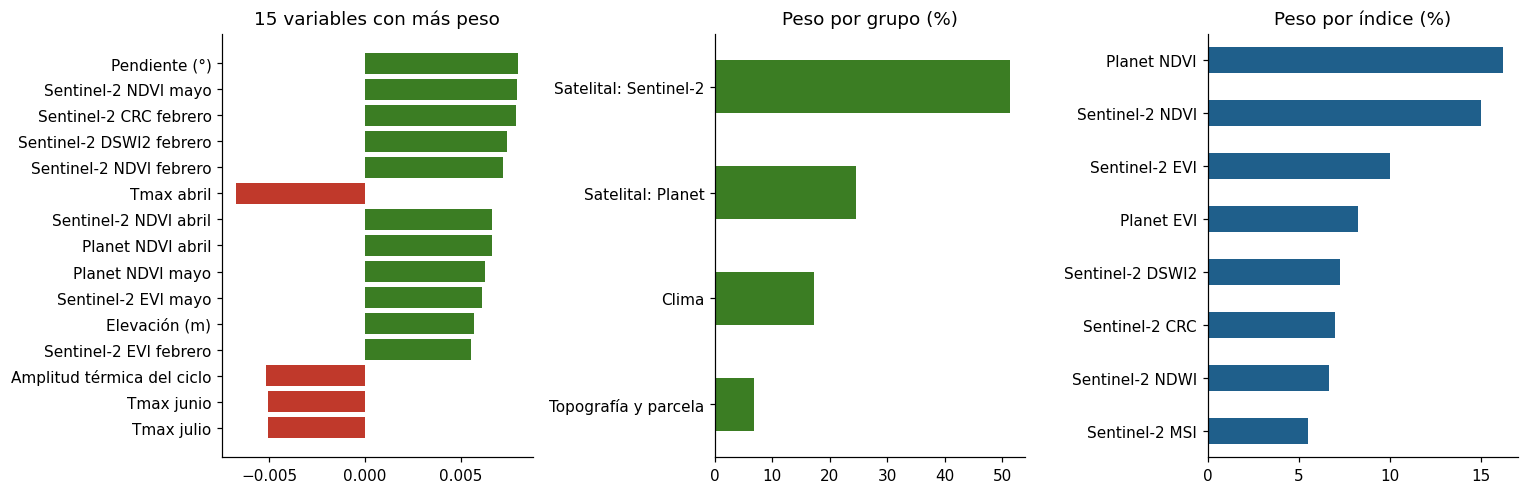

In [8]:
final = ModeloAgroCebada(anom).fit(tr)
pesos = final.pesos()
res_tr = (tr.rendimiento_t_ha - media_loo(tr)).values          # lo que el municipio no explica
pesos["r_con_residuo"] = [np.corrcoef(tr[v + "_anom"].fillna(tr[v + "_anom"].median()), res_tr)[0, 1] for v in pesos.variable]
print(f"Regularización elegida por validación interna (alpha): {final.alpha:.0f}")
display(pesos.head(15)[["etiqueta", "grupo", "coeficiente", "peso_pct", "r_con_residuo"]].round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
p15 = pesos.head(15).iloc[::-1]
ax[0].barh(p15.etiqueta, p15.coeficiente, color=[VERDE if c > 0 else ROJO for c in p15.coeficiente]); ax[0].set_title("15 variables con más peso")
pesos.groupby("grupo").peso_pct.sum().sort_values().plot.barh(ax=ax[1], color=VERDE); ax[1].set_title("Peso por grupo (%)"); ax[1].set_ylabel("")
pesos.dropna(subset=["familia_indice"]).groupby("familia_indice").peso_pct.sum().sort_values().plot.barh(ax=ax[2], color=AZUL); ax[2].set_title("Peso por índice (%)"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

In [9]:
# Respuestas a las preguntas guía 1 y 2 (calculadas con los pesos)
ind = pesos.dropna(subset=["familia_indice"]).groupby("familia_indice").peso_pct.sum().sort_values(ascending=False)
clima = pesos[pesos.grupo == "Clima"].head(3)
print("1) Índice con más peso:", ", ".join(f"{i} ({v:.1f} %)" for i, v in ind.head(3).items()))
print("2) Variables climáticas con más peso:", ", ".join(f"{r.etiqueta} ({r.peso_pct:.1f} %)" for r in clima.itertuples()))
corr = pesos.assign(a=pesos.r_con_residuo.abs()).sort_values("a", ascending=False).head(3)
print("   Mayor correlación con lo que el municipio no explica:", ", ".join(f"{r.etiqueta} (r = {r.r_con_residuo:.2f})" for r in corr.itertuples()))
print("   Advertencia: el clima tiene resolución de ~5 km (25 píxeles para 197 parcelas); gran parte de su señal es ubicación.")

1) Índice con más peso: Planet NDVI (16.2 %), Sentinel-2 NDVI (15.0 %), Sentinel-2 EVI (10.0 %)
2) Variables climáticas con más peso: Tmax abril (3.2 %), Amplitud térmica del ciclo (2.5 %), Tmax junio (2.4 %)
   Mayor correlación con lo que el municipio no explica: Sentinel-2 NDVI febrero (r = 0.26), Sentinel-2 NDVI mayo (r = 0.25), Sentinel-2 NDVI abril (r = 0.24)
   Advertencia: el clima tiene resolución de ~5 km (25 píxeles para 197 parcelas); gran parte de su señal es ubicación.


## ¿Qué combinación de variables funciona mejor? (pregunta guía 3)
Se repite la misma validación agregando grupos de variables a la línea base.

In [10]:
G = {g: [c for c in anom if grupo_variable(c) == g] for g in ["Satelital: Planet", "Satelital: Sentinel-2", "Clima", "Topografía y parcela"]}
sat, clm, top = G["Satelital: Planet"] + G["Satelital: Sentinel-2"], G["Clima"], G["Topografía y parcela"]
combos = {"Solo municipio (línea base)": [], "Municipio + satelital": sat, "Municipio + clima": clm,
          "Municipio + topografía y parcela": top, "Municipio + satelital + topografía": sat + top,
          "Municipio + satelital + clima": sat + clm, "Municipio + todas las variables": sat + clm + top}
filas = []
for nom, cols in combos.items():
    a, g = metricas(cv_modelo(rk, ModeloAgroCebada, cols)), metricas(cv_modelo(gk, ModeloAgroCebada, cols))
    filas.append({"Combinación": nom, "Variables": len(cols), "RMSE aleat.": a["RMSE"], "MAE aleat.": a["MAE"],
                  "RMSE agrup.": g["RMSE"], "R² agrup.": g["R2"]})
combinaciones = pd.DataFrame(filas).round(3)
display(combinaciones)
mejor = combinaciones.sort_values("RMSE agrup.").iloc[0]
print(f"Menor RMSE agrupado: {mejor['Combinación']} ({mejor['RMSE agrup.']:.3f} t/ha). Las diferencias son de ~0.01 t/ha: dentro del ruido.")

,Combinación,Variables,RMSE aleat.,MAE aleat.,RMSE agrup.,R² agrup.
0,Solo municipio (línea base),0,0.496,0.325,0.527,0.613
1,Municipio + satelital,55,0.492,0.335,0.525,0.617
2,Municipio + clima,16,0.501,0.338,0.527,0.614
3,Municipio + topografía y parcela,3,0.496,0.337,0.533,0.606
4,Municipio + satelital + topografía,58,0.492,0.338,0.524,0.618
5,Municipio + satelital + clima,71,0.494,0.335,0.524,0.619
6,Municipio + todas las variables,74,0.494,0.337,0.523,0.619


Menor RMSE agrupado: Municipio + todas las variables (0.523 t/ha). Las diferencias son de ~0.01 t/ha: dentro del ruido.


## Modelo final y predicciones
- **Error esperado:** se estima con las predicciones fuera de muestra (validación cruzada).
- **Rango de 80 %:** percentiles 10 y 90 de esos errores, sumados a cada predicción.
- Las 59 parcelas del reto se predicen con el modelo ajustado a las 138 parcelas de entrenamiento.

Modelo final (validación aleatoria): RMSE 0.494 | MAE 0.337 | R² 0.660
Línea base                         : RMSE 0.496 | MAE 0.325 | R² 0.658
Rango de 80 %: -0.52 a +0.54 t/ha alrededor de la predicción


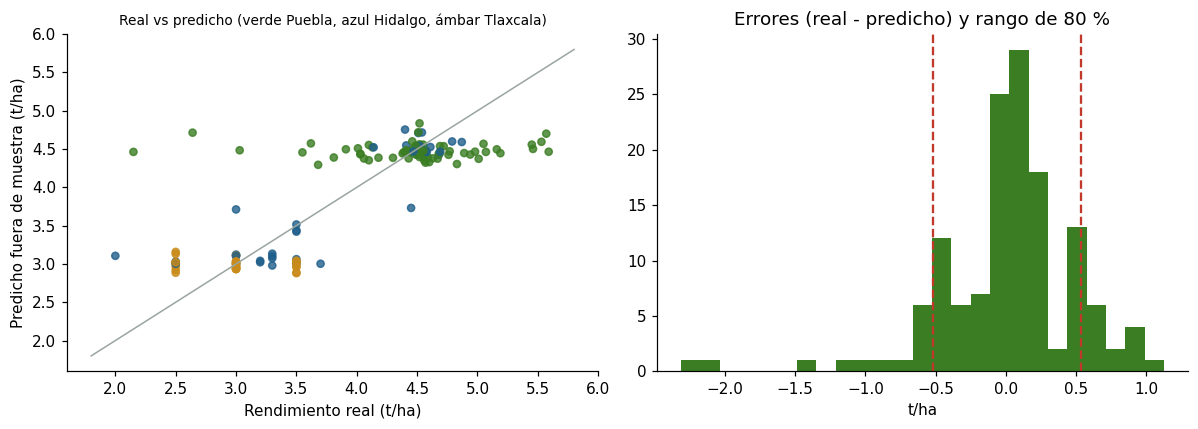

,ID_POLIGONO,Estado,Municipio,area_ha,RENDIMIENTO_T_HA_PREDICHO,P10,P90
2,AGC_003,Hidalgo,Singuilucan,18.68,3.346,2.829,3.882
10,AGC_011,Puebla,Chignahuapan,7.17,4.602,4.085,5.138
15,AGC_016,Puebla,Chignahuapan,7.47,4.374,3.857,4.910
24,AGC_025,Tlaxcala,Calpulalpan,2.00,2.984,2.467,3.520
26,AGC_027,Tlaxcala,Calpulalpan,8.46,2.956,2.439,3.492
27,AGC_028,Puebla,Chignahuapan,1.86,4.561,4.044,5.097
28,AGC_029,Tlaxcala,Calpulalpan,5.90,3.039,2.522,3.575
29,AGC_030,Hidalgo,Singuilucan,13.05,3.194,2.677,3.730
30,AGC_031,Puebla,Chignahuapan,1.98,4.497,3.980,5.033
35,AGC_036,Puebla,Chignahuapan,5.00,4.350,3.833,4.886


{'count': 59.0, 'mean': 3.93, 'std': 0.72, 'min': 2.57, '25%': 3.04, '50%': 4.39, '75%': 4.48, 'max': 4.63}


In [11]:
oof = cv_modelo(rk, ModeloAgroCebada)
q10, q90 = np.quantile(y - oof, [0.10, 0.90])
m = metricas(oof); mb = metricas(cv_modelo(rk, None))
print(f"Modelo final (validación aleatoria): RMSE {m['RMSE']:.3f} | MAE {m['MAE']:.3f} | R² {m['R2']:.3f}")
print(f"Línea base                         : RMSE {mb['RMSE']:.3f} | MAE {mb['MAE']:.3f} | R² {mb['R2']:.3f}")
print(f"Rango de 80 %: {q10:+.2f} a {q90:+.2f} t/ha alrededor de la predicción")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
col = tr.Estado.map({"Puebla": VERDE, "Hidalgo": AZUL, "Tlaxcala": "#C98B1A"})
ax[0].scatter(y, oof, c=col, s=22, alpha=.8); lim = [1.8, 5.8]; ax[0].plot(lim, lim, color=GRIS, lw=1)
ax[0].set_xlabel("Rendimiento real (t/ha)"); ax[0].set_ylabel("Predicho fuera de muestra (t/ha)"); ax[0].set_title("Real vs predicho (verde Puebla, azul Hidalgo, ámbar Tlaxcala)", fontsize=9)
ax[1].hist(y - oof, bins=25, color=VERDE); ax[1].axvline(q10, color=ROJO, ls="--"); ax[1].axvline(q90, color=ROJO, ls="--")
ax[1].set_title("Errores (real - predicho) y rango de 80 %"); ax[1].set_xlabel("t/ha")
plt.tight_layout(); plt.show()

# Predicciones de las 59 parcelas del reto
pr = t[t.conjunto == "PREDICCION"][["ID_POLIGONO", "Estado", "Municipio", "area_ha"]].copy()
pr["RENDIMIENTO_T_HA_PREDICHO"] = final.predict(t[t.conjunto == "PREDICCION"]).round(3)
pr["P10"] = (pr.RENDIMIENTO_T_HA_PREDICHO + q10).round(3); pr["P90"] = (pr.RENDIMIENTO_T_HA_PREDICHO + q90).round(3)
display(pr.head(10)); print(pr.RENDIMIENTO_T_HA_PREDICHO.describe().round(2).to_dict())

In [12]:
# Archivos de salida
pr[["ID_POLIGONO", "RENDIMIENTO_T_HA_PREDICHO"]].to_csv("predicciones_59_parcelas.csv", index=False)
pesos.round(5).to_csv("pesos_variables.csv", index=False)
combinaciones.to_csv("combinaciones.csv", index=False)
print("Generados: predicciones_59_parcelas.csv, pesos_variables.csv, combinaciones.csv")
try:
    from google.colab import files
    for f in ["predicciones_59_parcelas.csv", "pesos_variables.csv", "combinaciones.csv"]: files.download(f)
except ImportError:
    pass

Generados: predicciones_59_parcelas.csv, pesos_variables.csv, combinaciones.csv


## Fase 6 · Despliegue: usar el modelo en la aplicación web
La aplicación en Streamlit importa el mismo `modelo.py`. También se puede predecir una parcela nueva directamente desde aquí: solo hace falta el municipio; las variables que no se indiquen se toman como el promedio de su zona.

In [13]:
zonas = Zonas(t)
nueva = pd.DataFrame([{"Municipio": "Chignahuapan", "area_ha": 6.0, "s2_ndvi_m05": 0.62, "pl_evi_m05": 0.55}])
res, _ = predecir_nuevas(final, zonas, nueva, q10, q90)
display(res.round(2))

,Municipio,Estado,media_municipio,correccion,rendimiento_predicho,p10,p90,produccion_esperada_t
0,Chignahuapan,Puebla,4.48,0.32,4.8,4.28,5.34,28.8


## Conclusiones y limitaciones
- La **ubicación (municipio)** explica la mayor parte del rendimiento predecible; los índices satelitales y el clima ajustan la predicción con efectos pequeños (corrección típica < 0.1 t/ha).
- Los pesos muestran que los índices de vegetación (NDVI y EVI de marzo a mayo) y la Tmax de abril son los que más aportan, pero sin ganancia significativa sobre la línea base.
- **Limitaciones:** un solo ciclo agrícola, 138 parcelas, clima de ~5 km y rendimientos con valores repetidos. Con más ciclos y parcelas la señal satelital podría pesar más.

## Anexo · Uso de inteligencia artificial
Las bases del reto piden indicar dónde se usó IA y anexar los *prompts*. En este trabajo se usó Claude (Anthropic) para apoyar el análisis exploratorio, la preparación de datos, el modelado y la aplicación web. **Pega aquí los prompts utilizados** (conversación completa) antes de entregar.